# 01 – Exploration des données

**Question :** à quoi ressemblent les transactions simulées, et qu'est-ce qui distingue une fraude d'une opération normale ?

Les données viennent du générateur v2 (`src/generator/generate_dataset.py`), lancé avec :
```bash
python -m src.generator.generate_dataset --n 250000 --days 30 --test-days 7 --test-fraud-rate 0.003 --seed 42
```
Deux fichiers : `data/transactions.csv` (30 jours, entraînement) et `data/transactions_test.csv` (7 jours suivants, test).
Le fichier `*_scenarios.csv` indique le scénario de chaque fraude : il sert **uniquement à l'analyse**, jamais à l'entraînement.

In [1]:
# Préparation : on travaille depuis la racine du projet pour importer src/ et config/
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E3E7EF", "axes.axisbelow": True})
AMBRE, ROUGE, TURQUOISE, GRIS = "#E89A00", "#E5384A", "#1BA597", "#C9D2E3"

In [2]:
from config.settings import DATA_DIR, DATASET_PATH
from src.common.schema import FIELDS

df = pd.read_csv(DATASET_PATH)
test = pd.read_csv(DATA_DIR / "transactions_test.csv")
for name, d in (("entraînement", df), ("test", test)):
    print(f"{name:13s} {len(d):>7,} transactions, {d.is_fraud.sum():>5,} fraudes ({d.is_fraud.mean():.2%}), "
          f"du {d.timestamp.min()[:10]} au {d.timestamp.max()[:10]}".replace(",", " "))
assert list(df.columns) == list(FIELDS), "le CSV doit respecter exactement le contrat de données"
df.head()

entraînement  203 141 transactions  4 034 fraudes (1.99%)  du 2026-08-31 au 2026-09-30
test           46 566 transactions    142 fraudes (0.30%)  du 2026-09-30 au 2026-10-07


,transaction_id,timestamp,sender_id,receiver_id,tx_type,amount,sender_balance_before,sender_balance_after,receiver_balance_before,receiver_balance_after,operator,channel,city,device_id,is_fraud
0,36c41d0b-cfec-5ea5-0000-000000000001,2026-08-31T23:05:34+00:00,237600012457,237700000183,CASH_IN,14000.0,84962.0,98962.0,4224051.0,4210051.0,MTN_MOMO,AGENT,Yaounde,dev-f44537816f47,0
1,3ddf0870-1cd5-bd46-0000-000000000002,2026-08-31T23:08:04+00:00,237600008392,237700000087,CASH_IN,9500.0,35907.0,45407.0,2520486.0,2510986.0,ORANGE_MONEY,AGENT,Kribi,dev-3ebae4f2ddfe,0
2,0e17ce6b-3b30-f435-0000-000000000003,2026-08-31T23:09:46+00:00,237600002027,237700000242,CASH_IN,13500.0,3336.0,16836.0,1780934.0,1767434.0,ORANGE_MONEY,AGENT,Douala,dev-d397f955327e,0
3,13e20e4a-0a9d-4bcc-0000-000000000004,2026-08-31T23:09:56+00:00,237600009843,237800000395,PAYMENT,3000.0,77200.0,74200.0,4030847.0,4033847.0,MTN_MOMO,USSD,Bamenda,dev-7323316eafbe,0
4,301ce891-667f-669f-0000-000000000005,2026-08-31T23:10:11+00:00,237600008284,237700000291,CASH_OUT,8000.0,92864.0,84864.0,2637232.0,2645232.0,MTN_MOMO,USSD,Douala,dev-275a8bfa4a90,0


## 1. Des classes très déséquilibrées
Environ 2 % de fraudes à l'entraînement et **0,3 %** sur la période de test (proche de la réalité).
Conséquence : l'*accuracy* est inutilisable (prédire « jamais de fraude » donnerait 99,7 %). On mesure avec l'**AUC-PR**, le **rappel** et la **précision**.

## 2. Les cinq scénarios de fraude

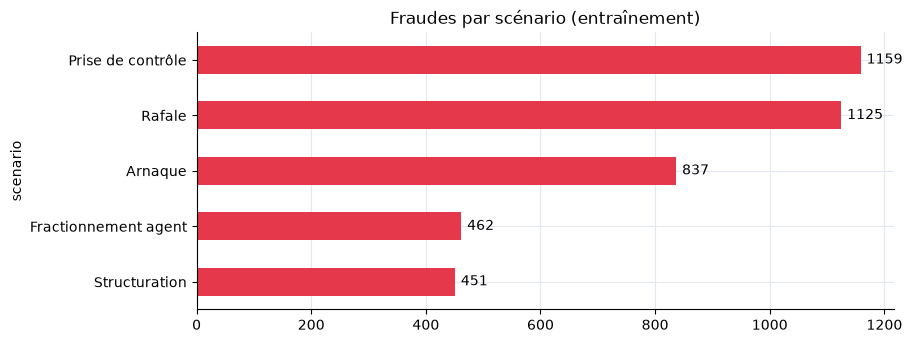

Rafales légitimes (pièges, is_fraud = 0) : 2010


In [3]:
sc = pd.read_csv(DATA_DIR / "transactions_scenarios.csv", usecols=["transaction_id", "fraud_scenario"])
noms = {"ATO": "Prise de contrôle", "VELOCITY": "Rafale", "SCAM": "Arnaque",
        "STRUCTURING": "Structuration", "AGENT_SPLIT": "Fractionnement agent", "LEGIT_BURST": "Rafale légitime"}
d = df.merge(sc, on="transaction_id", how="left")
d["scenario"] = d["fraud_scenario"].map(noms)
fraudes = d[d.is_fraud == 1]["scenario"].value_counts()
ax = fraudes.sort_values().plot.barh(color=ROUGE, title="Fraudes par scénario (entraînement)")
for i, v in enumerate(fraudes.sort_values()): ax.text(v + 10, i, v, va="center")
plt.show()
print("Rafales légitimes (pièges, is_fraud = 0) :", (d.fraud_scenario == "LEGIT_BURST").sum())

| Scénario | Comportement | Ce qui le trahit |
|---|---|---|
| Prise de contrôle | appareil inconnu, souvent la nuit, mule qui retire aussitôt | nouvel appareil, nouveau destinataire |
| Rafale | 5 à 10 petits transferts en moins de 3 minutes | nombre d'opérations en 10 min |
| Arnaque | la victime envoie elle-même un gros montant | montant inhabituel, destinataire inconnu |
| Structuration | transferts répétés juste sous 100 000 XAF | nombre d'opérations en 1 h, montants proches du seuil |
| Fractionnement agent | un dépôt découpé en petits dépôts chez le même agent | même expéditeur → même destinataire répété |

## 3. Quelles opérations sont touchées ?

In [4]:
par_type = df.groupby("tx_type").agg(transactions=("is_fraud", "size"), taux_fraude=("is_fraud", "mean"))
par_type["taux_fraude"] = (par_type["taux_fraude"] * 100).round(2)
par_type.sort_values("taux_fraude", ascending=False)

,transactions,taux_fraude
tx_type,,
TRANSFER,56081,5.67
CASH_IN,54727,0.84
CASH_OUT,49110,0.80
AIRTIME,15301,0.00
PAYMENT,27922,0.00


## 4. Le rythme de la journée (heure locale du Cameroun, UTC+1)

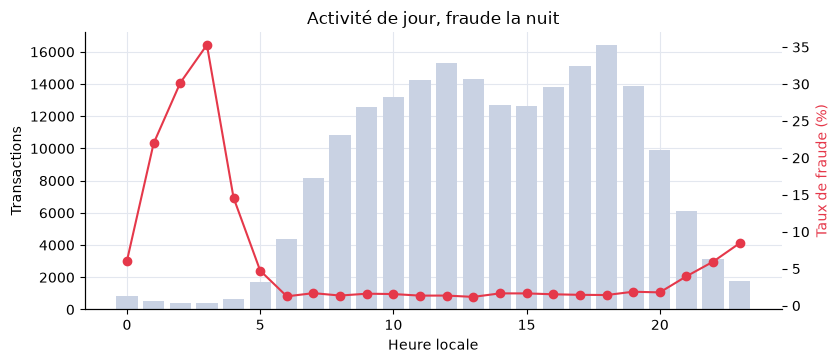

Taux de fraude moyen : nuit (0-5 h) 21.6%, journée (8-20 h) 1.5%


In [5]:
heure = (pd.to_datetime(df.timestamp, utc=True) + pd.Timedelta(hours=1)).dt.hour
h = df.assign(heure=heure).groupby("heure").agg(n=("is_fraud", "size"), taux=("is_fraud", "mean"))
fig, ax = plt.subplots()
ax.bar(h.index, h["n"], color=GRIS); ax.set_xlabel("Heure locale"); ax.set_ylabel("Transactions")
ax2 = ax.twinx(); ax2.plot(h.index, h["taux"] * 100, color=ROUGE, marker="o"); ax2.set_ylabel("Taux de fraude (%)", color=ROUGE)
ax2.grid(False); ax.set_title("Activité de jour, fraude la nuit"); plt.show()
nuit, jour = h.loc[0:4, "taux"].mean(), h.loc[8:19, "taux"].mean()
print(f"Taux de fraude moyen : nuit (0-5 h) {nuit:.1%}, journée (8-20 h) {jour:.1%}")

## 5. Les montants

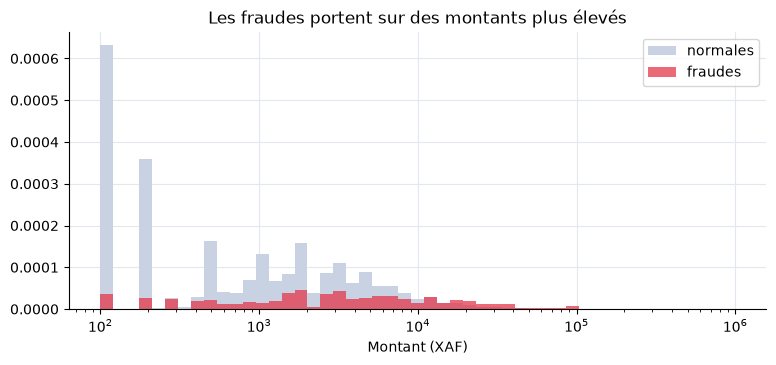

              50%     mean       max
is_fraud                            
0          6500.0  12948.0  988500.0
1         22000.0  35528.0  495000.0
Plafond KYC respecté (aucune dépense > 500 000 XAF) : True


In [6]:
import numpy as np
bins = np.logspace(2, np.log10(df.amount.max()), 50)
fig, ax = plt.subplots()
ax.hist(df.amount[df.is_fraud == 0], bins=bins, density=True, color=GRIS, label="normales")
ax.hist(df.amount[df.is_fraud == 1], bins=bins, density=True, color=ROUGE, alpha=.75, label="fraudes")
ax.set_xscale("log"); ax.set_xlabel("Montant (XAF)"); ax.legend(); ax.set_title("Les fraudes portent sur des montants plus élevés")
plt.show()
print(df.groupby("is_fraud")["amount"].describe()[["50%", "mean", "max"]].round(0))
print("Plafond KYC respecté (aucune dépense > 500 000 XAF) :",
      bool((df.loc[df.tx_type != "CASH_IN", "amount"] <= 500_000).all()))

## Ce qu'il faut retenir
- Les fraudes sont rares (2 % puis 0,3 %) : on évalue avec l'AUC-PR, jamais avec l'accuracy.
- Elles touchent surtout les transferts et les retraits, plus souvent la nuit, avec des montants plus élevés…
- … mais **aucune variable isolée ne suffit** : les distributions se recouvrent. Il faut comparer chaque transaction **aux habitudes du compte** et à son **activité récente** : c'est l'objet du notebook 02.